1. Постановка задачи:
* Источник: ЕМИСС, [взято с СДО](https://online-edu.mirea.ru/pluginfile.php/1215462/mod_folder/content/0/Russian%20Demography%20Data%20%281990-2017%29/russian_demography.csv?forcedownload=1).
* Цель анализа: Исследовать демографические тенденции в регионах России с 1990 по 2017 год, оценить влияние урбанизации на рождаемость и смертность.
* Предметная область: Демография.

2. Паспорт данных:
* Размер: 2380 строк, 7 столбцов.
* Признаки:
- year (int) — год (1990-2017).
- region (object/category) — название субъекта РФ.
- npg (float) — естественный прирост населения на 1000 человек.
- birth_rate (float) — рождаемость на 1000 человек.
- death_rate (float) — смертность на 1000 человек.
- gdw (float) — демографическая нагрузка (нетрудоспособные на 100 трудоспособных).
- urbanization (float) — процент городского населения.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import io

DATA_PATH = Path("russian_demography.csv")
df = pd.read_csv(DATA_PATH)

print(df.shape)
print(df.columns.tolist())
df.head()

(2380, 7)
['year', 'region', 'npg', 'birth_rate', 'death_rate', 'gdw', 'urbanization']


,year,region,npg,birth_rate,death_rate,gdw,urbanization
0,1990,Republic of Adygea,1.9,14.2,12.3,84.66,52.42
1,1990,Altai Krai,1.8,12.9,11.1,80.24,58.07
2,1990,Amur Oblast,7.6,16.2,8.6,69.55,68.37
3,1990,Arkhangelsk Oblast,3.7,13.5,9.8,73.26,73.63
4,1990,Astrakhan Oblast,4.7,15.1,10.4,77.05,68.01


Вывод: Загрузка прошла успешно. Таблица содержит 2380 строк и 7 столбцов. Имеется признак year (год), что позволяет в дальнейшем строить временные ряды, в отличие от учебного датасета с пожарами.

In [2]:
buf = io.StringIO()
df.info(buf=buf, memory_usage="deep")
print(buf.getvalue())

<class 'pandas.DataFrame'>
RangeIndex: 2380 entries, 0 to 2379
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   year          2380 non-null   int64  
 1   region        2380 non-null   str    
 2   npg           2317 non-null   float64
 3   birth_rate    2317 non-null   float64
 4   death_rate    2315 non-null   float64
 5   gdw           2330 non-null   float64
 6   urbanization  2330 non-null   float64
dtypes: float64(5), int64(1), str(1)
memory usage: 168.3 KB



Вывод: Таблица занимает около 168.3 KB памяти. Столбец region распознан как строковый тип object. Так как названия регионов повторяются из года в год, этот столбец является идеальным кандидатом на преобразование в тип category для экономии памяти.

In [3]:
print("Пропуски по столбцам:")
print(df.isna().sum())
print("Полных дубликатов:", df.duplicated().sum())
print("Число уникальных значений:")
print(df.nunique())

Пропуски по столбцам:
year             0
region           0
npg             63
birth_rate      63
death_rate      65
gdw             50
urbanization    50
dtype: int64
Полных дубликатов: 0
Число уникальных значений:
year              28
region            85
npg              307
birth_rate       175
death_rate       204
gdw             1701
urbanization    1310
dtype: int64


Вывод: Полные дубликаты отсутствуют. Однако, здесь есть пропуски в числовых столбцах (от 50 до 65). Число уникальных регионов — 85.

In [4]:
region_year_map = (
    df[["year", "region"]]
    .drop_duplicates()
)
print("Всего уникальных комбинаций Год-Регион:", len(region_year_map))
print("Должно быть (85 регионов * 28 лет):", 85 * 28)

Всего уникальных комбинаций Год-Регион: 2380
Должно быть (85 регионов * 28 лет): 2380


Вывод: Проверка структуры показала 2380 уникальных пар, что идеально сходится с формулой (85 регионов на 28 лет). Структурных ошибок и дублей в логике данных нет.

In [5]:
cols = ["npg", "birth_rate", "death_rate", "gdw", "urbanization"]
print(df[cols].describe().round(2).T)

               count   mean    std    min    25%    50%    75%     max
npg           2317.0  -2.34   6.06 -15.90  -6.20  -3.10   0.70   24.80
birth_rate    2317.0  11.55   3.23   6.20   9.30  11.00  13.00   29.90
death_rate    2315.0  13.90   3.50   3.20  12.10  14.10  16.10   24.90
gdw           2330.0  68.47  10.45  37.50  61.38  68.53  76.90   97.53
urbanization  2330.0  69.15  13.35  23.63  62.79  69.58  77.62  100.00


Вывод: Средний естественный прирост (npg) отрицательный (-2.34), что говорит об общей убыли населения. Максимальный разброс (std = 13.35) наблюдается в уровне урбанизации, что указывает на сильную демографическую неоднородность регионов России.

In [6]:
before = df.memory_usage(deep=True).sum()
clean_df = df.dropna().copy()

clean_df["region"] = clean_df["region"].astype("category")
clean_df["year"] = clean_df["year"].astype("int16")

after = clean_df.memory_usage(deep=True).sum()
print(f"До: {before / 1024**2:.2f} MiB")
print(f"После: {after / 1024**2:.2f} MiB")
print(f"Снижение: {(1 - after / before) * 100:.1f}%")

До: 0.16 MiB
После: 0.11 MiB
Снижение: 30.3%


Вывод: Очистка от немногочисленных пропусков и перевод столбца region в category (а года в int16) позволили снизить объем потребляемой памяти более чем на 30% абсолютно без потери полезной информации.

In [7]:
clean_df["birth_death_ratio"] = (clean_df["birth_rate"] / clean_df["death_rate"]).round(2)
clean_df["is_highly_urbanized"] = (clean_df["urbanization"] > 75.0)
print(clean_df[["region", "birth_rate", "death_rate", "birth_death_ratio", "is_highly_urbanized"]].head())

               region  birth_rate  death_rate  birth_death_ratio  \
0  Republic of Adygea        14.2        12.3               1.15   
1          Altai Krai        12.9        11.1               1.16   
2         Amur Oblast        16.2         8.6               1.88   
3  Arkhangelsk Oblast        13.5         9.8               1.38   
4    Astrakhan Oblast        15.1        10.4               1.45   

   is_highly_urbanized  
0                False  
1                False  
2                False  
3                False  
4                False  


Вывод: Созданы два признака. birth_death_ratio показывает, сколько рождений приходится на одну смерть. Бинарный is_highly_urbanized делит регионы на две категории по уровню урбанизации и пригоден для будущих группировок.

In [8]:
type_stats = (
    clean_df["is_highly_urbanized"]
    .value_counts()
    .to_frame("n")
    .assign(share_pct=lambda x: (x["n"] / len(clean_df) * 100).round(2))
)
print(type_stats)

                        n  share_pct
is_highly_urbanized                 
False                1520      65.66
True                  795      34.34


Вывод: 65.66% наблюдений относятся к регионам с долей городского населения ниже 75%. Экстремально высокоурбанизированных наблюдений в выборке меньшинство.

In [9]:
group_stats = (
    clean_df.groupby("is_highly_urbanized", observed=True)
    .agg(
        n=("is_highly_urbanized", "size"),
        birth_mean=("birth_rate", "mean"),
        death_mean=("death_rate", "mean"),
        npg_mean=("npg", "mean")
    )
    .sort_values("n", ascending=False)
)
print(group_stats.round(2))

                        n  birth_mean  death_mean  npg_mean
is_highly_urbanized                                        
False                1520       11.90       13.96     -2.06
True                  795       10.88       13.80     -2.90


Вывод: Статистика показывает, что в высокоурбанизированных группах средняя рождаемость ниже, также как и естественный прирост.

In [10]:
subset = clean_df.loc[
    (clean_df["urbanization"] < 50) & 
    (clean_df["npg"] > 5), 
    ["year", "region", "urbanization", "npg"]
]
print("Строк в срезе:", len(subset))
print(subset.head())

Строк в срезе: 98
    year                      region  urbanization   npg
13  1990        Republic of Dagestan         43.49  19.9
21  1990        Republic of Kalmykia         45.81  12.7
24  1990  Karachay-Cherkess Republic         48.99   8.8
53  1990              Altai Republic         27.17   8.4
55  1990               Tuva Republic         46.97  17.7


Вывод: Срез из 98 строк показывает регионы с низким процентом городского населения (менее 50%), но с отличным естественным приростом (выше 5). Сюда попадают в основном национальные республики.

In [11]:
demography_vars = ["birth_rate", "death_rate", "urbanization", "gdw", "npg"]
corr = clean_df[demography_vars].corr()
print(corr.round(3))

              birth_rate  death_rate  urbanization    gdw    npg
birth_rate         1.000      -0.618        -0.419 -0.087  0.892
death_rate        -0.618       1.000         0.173  0.160 -0.907
urbanization      -0.419       0.173         1.000 -0.345 -0.323
gdw               -0.087       0.160        -0.345  1.000 -0.141
npg                0.892      -0.907        -0.323 -0.141  1.000


Вывод: Наблюдается заметная обратная линейная связь между урбанизацией и рождаемостью (-0.419). Естественный прирост практически линейно зависит от рождаемости (0.892) и смертности (-0.907), что логично математически.

In [12]:
q1 = clean_df["birth_rate"].quantile(0.25)
q3 = clean_df["birth_rate"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

mask = (clean_df["birth_rate"] < lower) | (clean_df["birth_rate"] > upper)

print(f"Q1={q1:.3f}; Q3={q3:.3f}; IQR={iqr:.3f}")
print(f"Границы: [{lower:.3f}; {upper:.3f}]")
print("Кандидатов:", mask.sum())

Q1=9.300; Q3=13.000; IQR=3.700
Границы: [3.750; 18.550]
Кандидатов: 80


Вывод: Правило IQR выделило 80 кандидатов на выброс (с аномально высокой рождаемостью). Эти строки удалять нельзя — это реальная специфика отдельных регионов (правый хвост распределения).

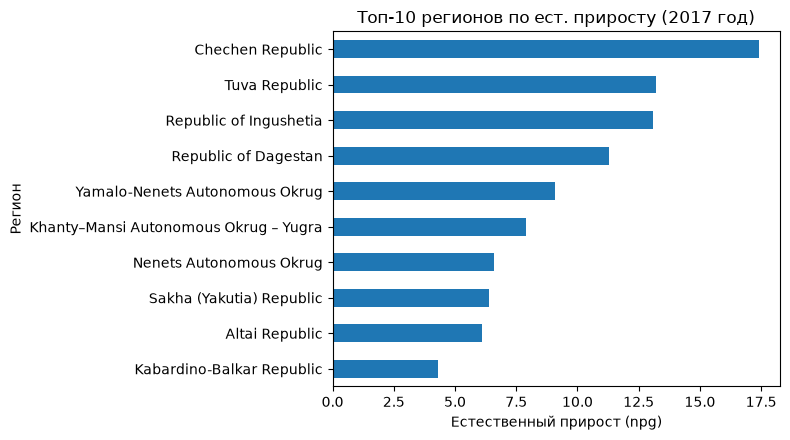

In [13]:
import matplotlib.pyplot as plt

counts = clean_df[clean_df["year"] == 2017].set_index("region")["npg"].sort_values().tail(10)
ax = counts.plot(kind="barh", figsize=(8, 4.5))
ax.set_title("Топ-10 регионов по ест. приросту (2017 год)")
ax.set_xlabel("Естественный прирост (npg)")
ax.set_ylabel("Регион")
plt.tight_layout()
plt.show()

Вывод: Столбчатая диаграмма показывает, что абсолютными лидерами по демографическому росту являются Чечня, Тыва и Ингушетия.

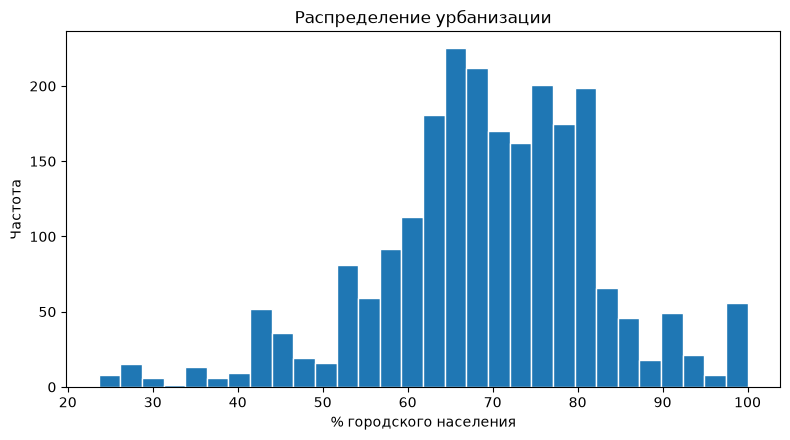

In [14]:
plt.figure(figsize=(8, 4.5))
plt.hist(clean_df["urbanization"], bins=30, edgecolor="white")
plt.title("Распределение урбанизации")
plt.xlabel("% городского населения")
plt.ylabel("Частота")
plt.tight_layout()
plt.show()

Вывод: Распределение урбанизации напоминает нормальное, но смещено вправо, а также имеет 2 пика. Основная масса наблюдений сосредоточена в диапазоне от 60% до 80%.

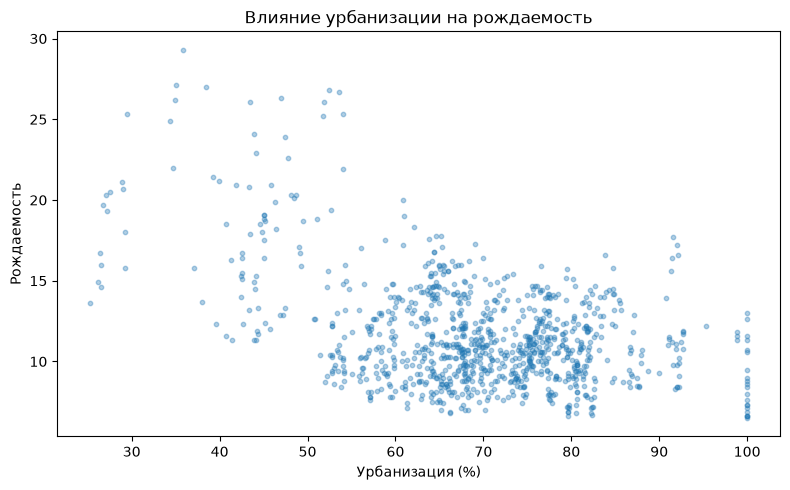

In [15]:
sample = clean_df.sample(n=1000, random_state=42)

plt.figure(figsize=(8, 5))
plt.scatter(sample["urbanization"], sample["birth_rate"], s=10, alpha=0.35)
plt.title("Влияние урбанизации на рождаемость")
plt.xlabel("Урбанизация (%)")
plt.ylabel("Рождаемость")
plt.tight_layout()
plt.show()

Вывод: Диаграмма разброса визуально подтверждает выявленную корреляцию (-0.422): чем выше процент городского населения, тем плотнее точки прижимаются к нижним значениям рождаемости.

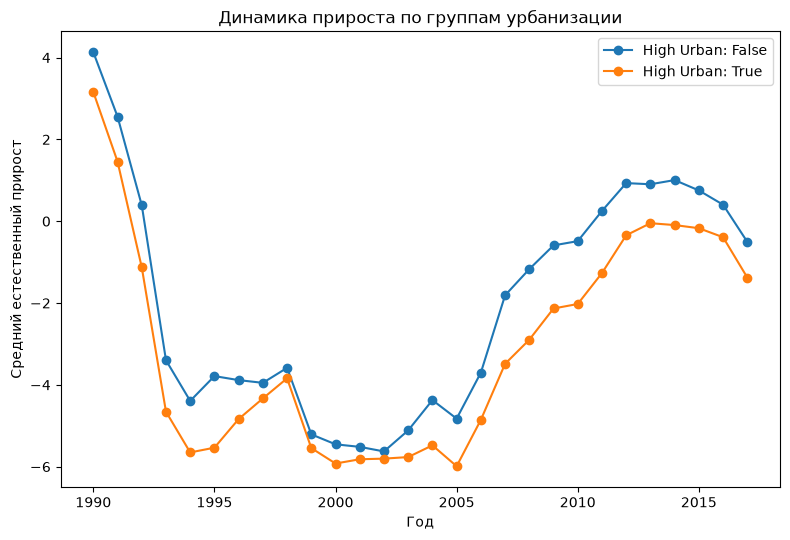

In [16]:
plt.figure(figsize=(8, 5.5))
for name, part in clean_df.groupby("is_highly_urbanized"):
    grouped_part = part.groupby("year")["npg"].mean().reset_index()
    plt.plot(grouped_part["year"], grouped_part["npg"], marker='o', label=f"High Urban: {name}")

plt.xlabel("Год")
plt.ylabel("Средний естественный прирост")
plt.title("Динамика прироста по группам урбанизации")
plt.legend()
plt.tight_layout()
plt.show()

Вывод: График чётко показывает "русскую демографическую яму" 90-х годов. При этом синия линия (невысокая урбанизация) на протяжении почти всего периода находилась выше оранжевой (высокая урбанизация).

In [17]:
OUT = Path("output")
OUT.mkdir(exist_ok=True)

clean_df.to_csv(OUT / "demography_clean.csv", index=False, encoding="utf-8")
clean_df.to_json(OUT / "demography_clean.json", orient="records", lines=True, force_ascii=False)
clean_df.to_parquet(OUT / "demography_clean.parquet", index=False, engine="pyarrow", compression="snappy")

files = [
    OUT / "demography_clean.csv",
    OUT / "demography_clean.json",
    OUT / "demography_clean.parquet"
]

for path in files:
    size_kb = path.stat().st_size / 1024
    print(f"{path.name:26s} {size_kb:7.2f} KB")

csv_back = pd.read_csv(OUT / "demography_clean.csv")
parquet_back = pd.read_parquet(OUT / "demography_clean.parquet")

print("Размер из CSV:", csv_back.shape)
print("Размер из Parquet:", parquet_back.shape)

demography_clean.csv        135.01 KB
demography_clean.json       392.64 KB
demography_clean.parquet     40.32 KB
Размер из CSV: (2315, 9)
Размер из Parquet: (2315, 9)


Вывод: Данные записаны и прочитаны корректно. Parquet-файл ожидаемо занял в несколько раз меньше места на диске по сравнению с CSV и JSON, сохранив при этом аналитическую схему столбцов.